In [6]:
# %pip install xlrd

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_excel(
    "/workspace/data/sample_-_superstore.xls",
    sheet_name="Orders" # on récupère l'onglet dans le fichier xls Orders
)

df.info()

# Nom du tableau utilisé dans la suite du cours
orders = df

<class 'pandas.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          10194 non-null  int64         
 1   Order ID        10194 non-null  str           
 2   Order Date      10194 non-null  datetime64[us]
 3   Ship Date       10194 non-null  datetime64[us]
 4   Ship Mode       10194 non-null  str           
 5   Customer ID     10194 non-null  str           
 6   Customer Name   10194 non-null  str           
 7   Segment         10194 non-null  str           
 8   Country/Region  10194 non-null  str           
 9   City            10194 non-null  str           
 10  State/Province  10194 non-null  str           
 11  Postal Code     10194 non-null  object        
 12  Region          10194 non-null  str           
 13  Product ID      10194 non-null  str           
 14  Category        10194 non-null  str           
 15  Sub-Category 

In [2]:
print(orders.shape)
print(orders.columns.tolist())

(10194, 21)
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


In [4]:
print('Lignes :', len(orders))
print('Commandes distinctes :', orders['Order ID'].nunique())
print('Catégories :', orders['Category'].nunique())

Lignes : 10194
Commandes distinctes : 5111
Catégories : 3


In [6]:
# orders['Order ID'].unique()

In [7]:
# Exercice 01 

print( f" nombre de sous catégories {orders["Sub-Category"].nunique()}")

 nombre de sous catégories 17


In [8]:
# Regrouper les lignes par catégorie et compter les commandes
par_categorie = orders.groupby("Category")["Order ID"].agg(
    lignes="size",       # Nombre de lignes de commande
    commandes="nunique"  # Nombre de commandes distinctes
)

# Afficher les deux comptages par catégorie
par_categorie

,lignes,commandes
Category,,
Furniture,2201,1819
Office Supplies,6128,3812
Technology,1865,1560


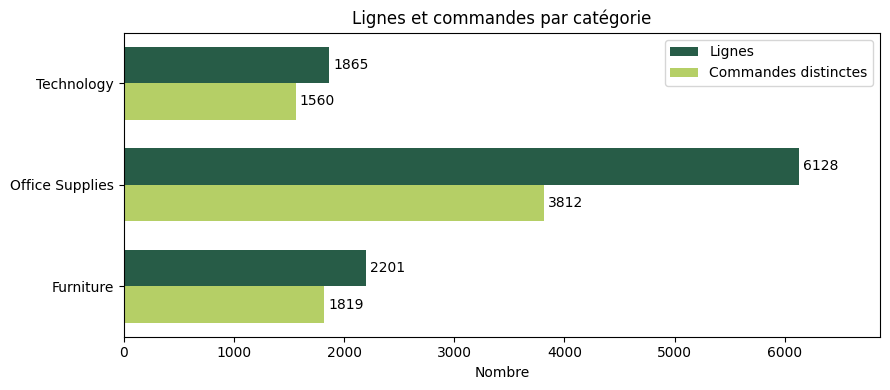

In [9]:
# Création d'une figure et de ses axes
# figsize définit la largeur et la hauteur en pouces
fig, ax = plt.subplots(figsize=(9, 4))

# Positions verticales des catégories : 0, 1, 2...
y = range(len(par_categorie))

# Première série : nombre de lignes par catégorie
# +0.18 décale les barres vers le haut
# height définit l'épaisseur des barres
b1 = ax.barh(
    [i + 0.18 for i in y],
    par_categorie["lignes"],
    height=0.36,
    label="Lignes",
    color="#275c47"
)

# Deuxième série : nombre de commandes distinctes
# -0.18 décale les barres vers le bas
b2 = ax.barh(
    [i - 0.18 for i in y],
    par_categorie["commandes"],
    height=0.36,
    label="Commandes distinctes",
    color="#b5cf66"
)

# Affichage des valeurs numériques au bout des barres
# padding=3 définit un espacement de 3 points
ax.bar_label(b1, padding=3)
ax.bar_label(b2, padding=3)

# Remplacement des positions 0, 1, 2...
# par les véritables noms des catégories
ax.set_yticks(list(y), par_categorie.index)

# Titre du graphique et nom de l'axe horizontal
ax.set(
    title="Lignes et commandes par catégorie",
    xlabel="Nombre"
)

# Affichage de la légende
ax.legend()

# Ajout d'une marge horizontale de 12 %
# pour laisser de la place aux valeurs affichées
ax.margins(x=0.12)

# Ajustement automatique des espacements
plt.tight_layout()

# Affichage du graphique
plt.show()

In [10]:
# Exercice 02 

par_region = orders.groupby("Region")["Order ID"].agg(
    lignes="size",
    commandes="nunique"
)

print(par_region)

         lignes  commandes
Region                    
Central    2335       1179
East       2986       1475
South      1620        822
West       3253       1635


### Exercice 02

Comparer les écarts par région

Dans quelle région l’écart entre lignes et commandes distinctes est-il le plus grand ?

*À rendre : La région, les deux comptages, l’écart et une phrase qui interprète cet écart.*

In [14]:
par_region = orders.groupby("Region")["Order ID"].agg(
    lignes="size", # nom de la fonction d'aggrégation
    commandes="nunique"
)

par_region # DataFrame 

,lignes,commandes
Region,,
Central,2335,1179
East,2986,1475
South,1620,822
West,3253,1635


In [17]:
par_region["ecart"] = abs( par_region["lignes"] - par_region["commandes"] )

In [18]:
par_region

,lignes,commandes,ecart
Region,,,
Central,2335,1179,1156
East,2986,1475,1511
South,1620,822,798
West,3253,1635,1618


In [21]:
region = par_region["ecart"].idxmax()
region

'West'

In [22]:
resultat = par_region.loc[region]
resultat

lignes       3253
commandes    1635
ecart        1618
Name: West, dtype: int64

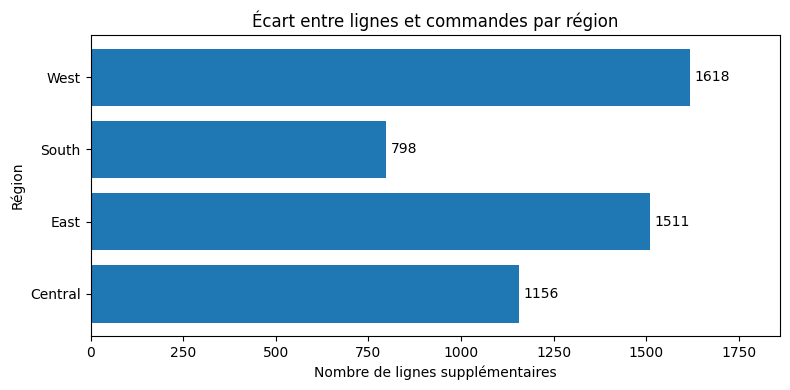

In [23]:
fig, ax = plt.subplots(figsize=(8, 4))

barres = ax.barh(par_region.index, par_region["ecart"])
ax.bar_label(barres, padding=3)

ax.set(
    title="Écart entre lignes et commandes par région",
    xlabel="Nombre de lignes supplémentaires",
    ylabel="Région"
)

ax.margins(x=0.15)
plt.tight_layout()
plt.show()

In [ ]:
    f"\nLa région {region} présente le plus grand écart "
    f"({resultat['ecart']} lignes supplémentaires). "
    "Cela traduit la présence de commandes contenant plusieurs "
    "lignes de produits, sans nécessairement indiquer "
    "un plus grand nombre de produits par commande."
)